# 16 · Análisis exploratorio: cantidad de árboles

**Etapa 21 del plan.** Los 296 árboles salieron del `03`, entrenando `A` con 2 meses (201905 y 201906) y deteniendo cuando la AUC de 201908 dejaba de mejorar. En el banco temporal del `15`, cada modelo entrena con 2 a 6 meses y con `BAJA+2` pesando el triple. Con más filas, el modelo puede necesitar más árboles.

**Pregunta:** sobre `ACH_4_P3`, ¿cuánto dinero suma usar más árboles?

**Regla fijada antes de correr:** la cantidad de árboles crece en proporción a las filas de entrenamiento. Da unos 292 en 201906 y unos 892 en 201910. La curva con 296, 450, 600, 750, 900 y 1.000 árboles se informa, pero no se elige el mejor punto después de verla.

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/15/` ni en los `resultados/03_*` a `15_*`:** solo los lee.

Ficha: `fichas/etapa_21_arboles.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee
EXP = Path('../exp/16')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
CONFIG = 'ACH_4_P3'                                  # la vigente del 15
COLUMNAS = JUNTAS
PESO_B2 = 3
ARBOLES_MAX = 1_000
CORTES = [296, 450, 600, 750, 900, 1_000]           # árboles con los que se guarda la predicción
FILAS_03 = 126_763 + 128_370                        # filas de 201905 y 201906: con ellas el 03 eligió los árboles
HIPOTESIS = 'Con más filas de entrenamiento hacen falta más árboles: proporcionales a las filas, ganan más que 296'
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[012345]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 41


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 2 s


## 3. Tablas

Las mismas columnas de `ACH_4` del `15`: 1.180, el baseline más la historia curada y los cuatro bloques del `14`.

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 23 s · memoria máxima 5.0 GB


## 4. Árboles por mes y controles

**Regla proporcional:** 296 × filas de entrenamiento ÷ 255.133, redondeado. 255.133 son las filas de 201905 y 201906, con las que el `03` eligió los 296.

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 5:** `ACH_4_P3` de 201906, con la primera semilla, entrenada con 346 árboles y cortada en 296, da la predicción del `15`. Comprueba las filas, las columnas, los bins, el peso y los hiperparámetros. En la corrida, además, cada modelo se compara con el `15` al llegar a 296 árboles.

**Control 11:** `ACH_4` tiene 1.180 columnas sin nombres repetidos, y las primeras 880 son las de `ACH`.

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == CORTES[0] == 296
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in MESES_EVALUADOS)        # control 3
FILAS_ENTRENA = {m: int(np.isin(T['mes_fila'], ENTRENA[m]).sum()) for m in MESES_EVALUADOS}
assert FILAS_03 == ESPERADO_FILAS_POR_MES[201905] + ESPERADO_FILAS_POR_MES[201906]


def proporcionales(arboles):
    return {m: int(round(arboles * FILAS_ENTRENA[m] / FILAS_03)) for m in MESES_EVALUADOS}


def ruta(nombre, mes, semilla):
    return EXP / 'pred' / nombre / str(mes) / f'{semilla}.npy'


def tabla_de(filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in CANDIDATAS])
    return X, T['columnas'][:k] + [c for b in CANDIDATAS for c in B[b][1]]


def entrenar(mes, semilla, arboles, dtrain=None, clase=None):
    if dtrain is None:
        entrena = np.isin(T['mes_fila'], ENTRENA[mes])
        X, columnas = tabla_de(entrena)
        clase = CLASE[T['filas'][entrena]]
        dtrain = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=False).construct()
        dtrain.set_weight(np.where(clase == 'BAJA+2', PESO_B2, 1).astype(np.float32))
    return lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=arboles)


print(pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                    'filas': FILAS_ENTRENA, 'árboles proporcionales': proporcionales(ARBOLES)}).to_string())

# Control 11
columnas_juntas = tabla_de(np.arange(2))[1]
assert len(columnas_juntas) == len(set(columnas_juntas)) == ESPERADO_N_VARIABLES[JUNTAS]
assert columnas_juntas[:ESPERADO_N_VARIABLES[BASE_CURADA]] == T['columnas'][:ESPERADO_N_VARIABLES[BASE_CURADA]]

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    modelo = entrenar(201906, SEMILLAS[0], ARBOLES + 50)      # más largo: comprueba también que cortar en 296 da lo mismo
    prob = modelo.predict(tabla_de(es_mes[201906])[0], num_iteration=ARBOLES, num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_15 / 'pred' / CONFIG / '201906' / f'{SEMILLAS[0]}.npy')), 'ACH_4_P3 no reproduce el 15'
    ruta_control.parent.mkdir(parents=True, exist_ok=True)
    ruta_control.write_text('ok\n')
    del modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s')
else:
    print('Control 5 ya hecho')
print('Controles 3 y 11 OK')
COMPARAR_CON_15 = True

       meses de entrenamiento   filas  árboles proporcionales
201906              201903-04  251738                     292
201907              201903-05  378501                     439
201908              201903-06  506871                     588
201909              201903-07  636724                     739
201910              201903-08  768499                     892
Control 5 OK en 30 s
Controles 3 y 11 OK


## 5. Modelos

Un modelo de 1.000 árboles por mes y semilla. Guarda la predicción con cada cantidad de la curva y con la proporcional de su mes. Los primeros árboles de un modelo largo son los mismos que los de uno corto, así que un solo entrenamiento da toda la curva.

**Retomar:** las predicciones de un modelo se guardan al terminarlo.

**Control 7:** hay predicción para cada cantidad, mes y semilla.

In [5]:
PROP = proporcionales(ARBOLES)
assert all(ARBOLES * 0.9 <= v <= ARBOLES_MAX for v in PROP.values()), PROP
NOMBRES_A = [f'A{c}' for c in CORTES] + ['PROP']
REFERENCIA = f'A{ARBOLES}'
arboles_de = lambda nombre, mes: PROP[mes] if nombre == 'PROP' else int(nombre[1:])

falta = lambda m, s: any(not ruta(n, m, s).exists() for n in NOMBRES_A)
print('Modelos pendientes:', sum(falta(m, s) for m in MESES_EVALUADOS for s in SEMILLAS))
segundos = []
for m in MESES_EVALUADOS:
    if not any(falta(m, s) for s in SEMILLAS):
        continue
    entrena = np.isin(T['mes_fila'], ENTRENA[m])
    X, columnas = tabla_de(entrena)
    clase = CLASE[T['filas'][entrena]]
    dtrain = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=False).construct()
    dtrain.set_weight(np.where(clase == 'BAJA+2', PESO_B2, 1).astype(np.float32))
    X_mes = tabla_de(es_mes[m])[0]
    for s in SEMILLAS:
        if not falta(m, s):
            continue
        t0 = time.time()
        modelo = entrenar(m, s, ARBOLES_MAX, dtrain, clase)
        for n in NOMBRES_A:
            prob = modelo.predict(X_mes, num_iteration=arboles_de(n, m), num_threads=N_HILOS).astype(np.float32)
            if n == REFERENCIA and COMPARAR_CON_15:
                assert np.array_equal(prob, np.load(EXP_15 / 'pred' / CONFIG / str(m) / f'{s}.npy')), ('no reproduce el 15', m, s)
            destino = ruta(n, m, s)
            assert destino.is_relative_to(EXP), destino
            destino.parent.mkdir(parents=True, exist_ok=True)
            np.save(destino, prob)
        segundos.append(time.time() - t0)
        print(f'{m} · semilla {s}: {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB', flush=True)
    del X, X_mes, dtrain, clase
    gc.collect()

PUNTAJE = {(n, m): np.stack([np.load(ruta(n, m, s)) for s in SEMILLAS]) for n in NOMBRES_A for m in MESES_EVALUADOS}
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())   # control 7
print('Predicciones completas:', len(PUNTAJE), 'grupos de', N_SEMILLAS, 'semillas')

Modelos pendientes: 25
201906 · semilla 294103: 84 s · memoria máxima 5.0 GB
201906 · semilla 342929: 90 s · memoria máxima 5.0 GB
201906 · semilla 161093: 97 s · memoria máxima 5.0 GB
201906 · semilla 677561: 98 s · memoria máxima 5.0 GB
201906 · semilla 431077: 97 s · memoria máxima 5.0 GB
201907 · semilla 294103: 133 s · memoria máxima 5.0 GB
201907 · semilla 342929: 132 s · memoria máxima 5.0 GB
201907 · semilla 161093: 134 s · memoria máxima 5.0 GB
201907 · semilla 677561: 135 s · memoria máxima 5.0 GB
201907 · semilla 431077: 135 s · memoria máxima 5.0 GB
201908 · semilla 294103: 170 s · memoria máxima 5.0 GB
201908 · semilla 342929: 169 s · memoria máxima 5.0 GB
201908 · semilla 161093: 170 s · memoria máxima 5.0 GB
201908 · semilla 677561: 171 s · memoria máxima 5.0 GB
201908 · semilla 431077: 176 s · memoria máxima 5.0 GB
201909 · semilla 294103: 206 s · memoria máxima 5.0 GB
201909 · semilla 342929: 204 s · memoria máxima 5.0 GB
201909 · semilla 161093: 208 s · memoria máxima

## 6. Comparaciones

Cada cantidad de árboles se compara contra 296, en los mismos modelos.

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla, como en el `15`.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** el desvío de la diferencia entre semillas. Acá las dos cantidades salen del mismo modelo, así que se mide la diferencia directamente.

El intervalo es la diferencia más o menos 1,96 errores totales.

In [6]:
B_MES = {(n, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(n, m)]]) for n, m in PUNTAJE}
filas = [{'arboles': n, 'arboles_mes': arboles_de(n, m), 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(n, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(n, m)][i]), 6)}
         for n, m in PUNTAJE for i, s in enumerate(SEMILLAS)]
meses_tabla = pd.DataFrame(filas)
meses_tabla.to_csv(RESULTADOS / '16_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(nombre):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in MESES_EVALUADOS:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(nombre, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(MESES_EVALUADOS) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


por_semilla = lambda nombre: np.mean([B_MES[(nombre, m)] for m in MESES_EVALUADOS], axis=0)
ensamble = lambda nombre: float(np.mean([banda(curva(PUNTAJE[(nombre, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in MESES_EVALUADOS]))

base = por_cliente(REFERENCIA)
filas = []
for j, n in enumerate(NOMBRES_A[1:]):
    d_cliente = por_cliente(n) - base
    d = d_cliente.sum() / 1e6
    dif_semilla = por_semilla(n) - por_semilla(REFERENCIA)
    assert abs(d - dif_semilla.mean()) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    e_s = dif_semilla.std(ddof=1) / np.sqrt(N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'arboles': n, 'contra': REFERENCIA, 'arboles_medios': np.mean([arboles_de(n, m) for m in MESES_EVALUADOS]),
                  'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t, 'd_ensamble_M': ensamble(n) - ensamble(REFERENCIA),
                  'semillas_a_favor': int((dif_semilla > 0).sum()),
                  **{f'd_{m}': B_MES[(n, m)].mean() - B_MES[(REFERENCIA, m)].mean() for m in MESES_EVALUADOS}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '16_comparacion.csv', index=False)

print('EXPLORATORIO')
print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({n: {m: B_MES[(n, m)].mean() for m in MESES_EVALUADOS} for n in NOMBRES_A}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['arboles', 'foto_mes'])['auc'].mean().unstack().loc[NOMBRES_A].round(4).to_string())

EXPLORATORIO
arboles contra  arboles_medios   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
   A450   A296           450.0  0.16              0.51             0.26           0.57       -0.96        1.28          0.18                 3      1.55      0.65     -1.25      0.71     -0.88
   A600   A296           600.0  0.09              0.76             0.14           0.77       -1.41        1.60          0.25                 3      1.29      0.94     -2.36      1.36     -0.75
   A750   A296           750.0 -0.28              1.01             0.20           1.03       -2.29        1.74         -0.05                 1      0.38      0.11     -2.91      1.90     -0.88
   A900   A296           900.0 -0.38              1.14             0.33           1.19       -2.72        1.95          0.05                 1     -0.12      0.08     -3.49      2.38     -0.76
  A1000   A296        

## 7. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

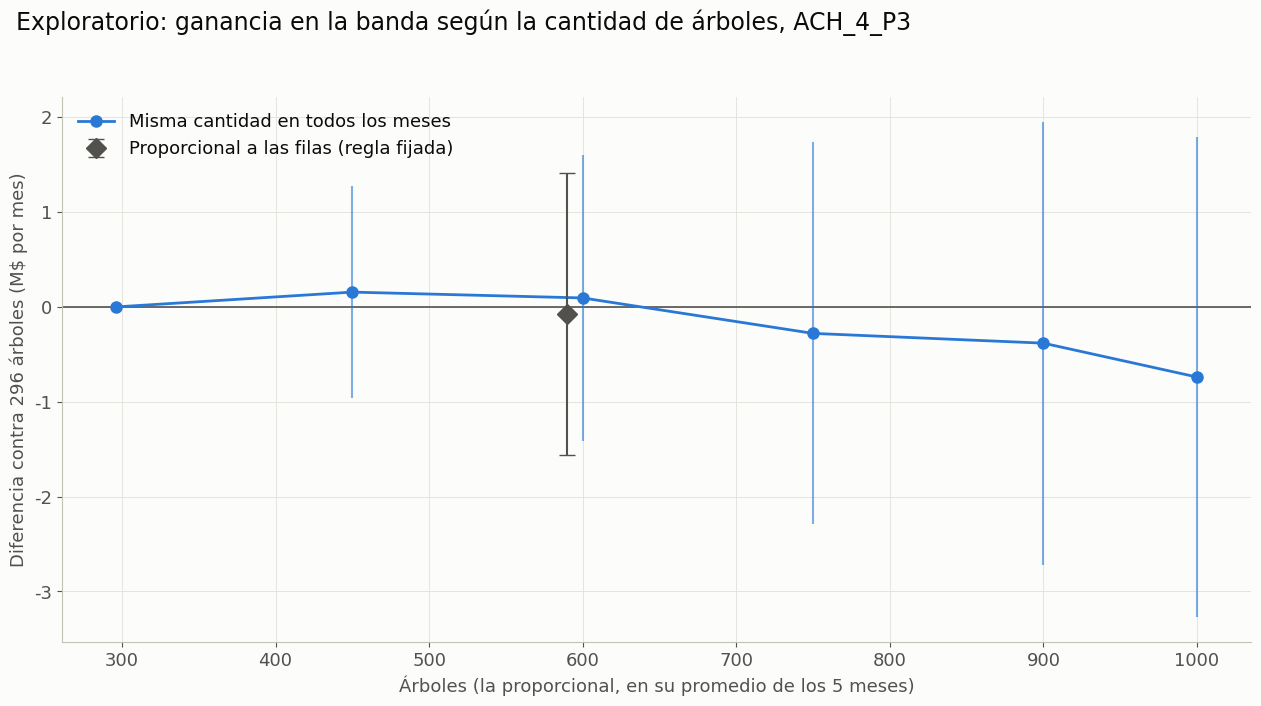

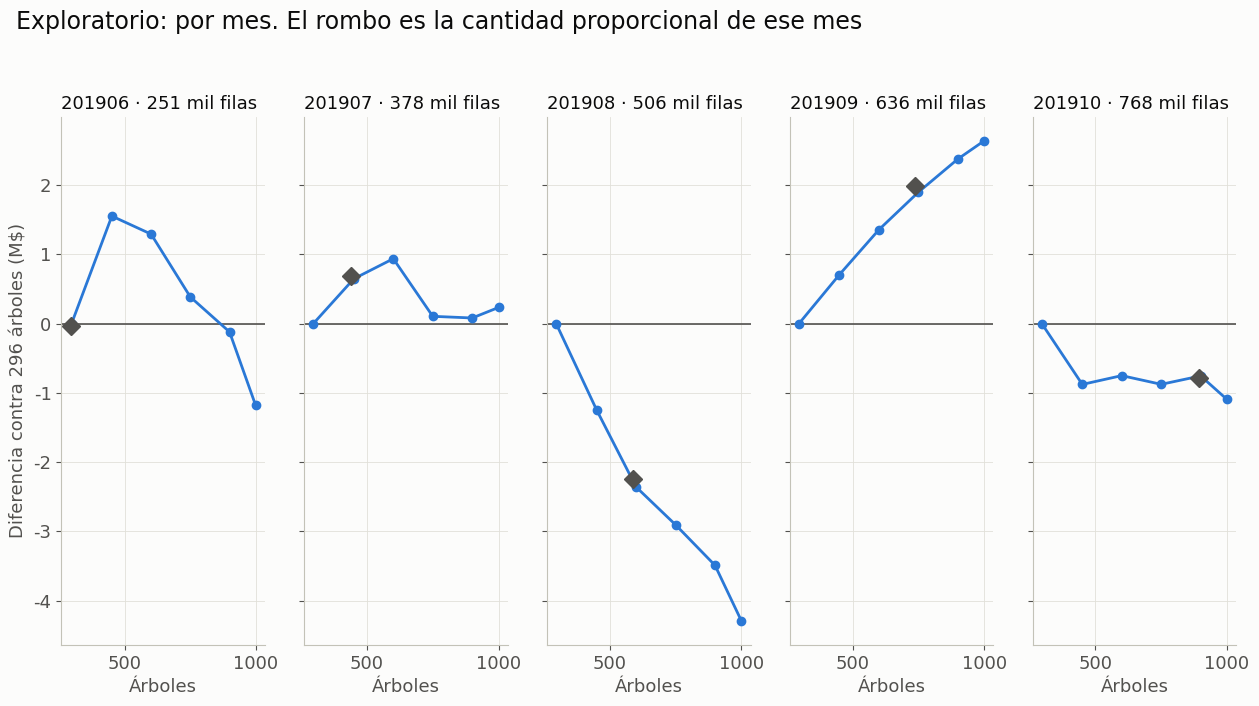

In [7]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


t = comparacion.set_index('arboles')
curva_n = [n for n in NOMBRES_A[1:] if n != 'PROP']
formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))

fig, ax = plt.subplots(figsize=TAMANO)
ax.axhline(0, color=TINTA_2, lw=1.2)
x = [ARBOLES] + [int(n[1:]) for n in curva_n]
ax.plot(x, [0] + list(t.loc[curva_n, 'd_M']), color=AZUL, lw=2, marker='o', ms=8, label='Misma cantidad en todos los meses')
ax.vlines(x[1:], t.loc[curva_n, 'ic95_inf_M'], t.loc[curva_n, 'ic95_sup_M'], color=AZUL, lw=1.5, alpha=0.6)
ax.errorbar(t.loc['PROP', 'arboles_medios'], t.loc['PROP', 'd_M'], yerr=1.96 * t.loc['PROP', 'error_total_M'], fmt='D', ms=10,
            color=TINTA_2, capsize=6, label='Proporcional a las filas (regla fijada)')
ax.yaxis.set_major_formatter(formato)
ax.set_xlabel('Árboles (la proporcional, en su promedio de los 5 meses)')
ax.set_ylabel('Diferencia contra 296 árboles (M$ por mes)')
ax.legend(frameon=False, loc='upper left')
fig.suptitle('Exploratorio: ganancia en la banda según la cantidad de árboles, ACH_4_P3', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '16_1_arboles.png', dpi=DPI)
plt.show()

fig, ejes = plt.subplots(1, len(MESES_EVALUADOS), figsize=TAMANO, sharey=True)
for ax, m in zip(ejes, MESES_EVALUADOS):
    ax.axhline(0, color=TINTA_2, lw=1.2)
    ax.plot(x, [0] + [t.loc[n, f'd_{m}'] for n in curva_n], color=AZUL, lw=2, marker='o', ms=6)
    ax.plot(PROP[m], t.loc['PROP', f'd_{m}'], 'D', ms=9, color=TINTA_2)
    ax.yaxis.set_major_formatter(formato)
    ax.set_title(f'{m} · {FILAS_ENTRENA[m] // 1000} mil filas', loc='left', fontsize=13)
    ax.set_xlabel('Árboles')
ejes[0].set_ylabel('Diferencia contra 296 árboles (M$)')
fig.suptitle('Exploratorio: por mes. El rombo es la cantidad proporcional de ese mes', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '16_2_por_mes.png', dpi=DPI)
plt.show()

## 8. Lectura fijada antes de correr

Decide solo la regla proporcional contra 296 árboles, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: desde ahora, los árboles son proporcionales a las filas |
| Entre −1 y +1 M | Empate: quedan los 296 |
| −1 M o menos | Resta: quedan los 296 |

La curva se informa, pero no decide: elegir el mejor punto después de verla sería ajustar al ruido. El intervalo se informa siempre.

**Control 8:** las salidas anteriores no cambiaron.

In [8]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print(f'Segundos por modelo: {np.mean(segundos):.1f}')
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    marca = ' · DECIDE' if r.arboles == 'PROP' else ''
    print(f'{r.arboles} ({r.arboles_medios:.0f} árboles en promedio) contra {r.contra}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · '
          f'error {r.error_total_M:.2f} M · ensamble {r.d_ensamble_M:+.2f} M · semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {lectura(r.d_M)}{marca}')

fila_prop = comparacion.set_index('arboles').loc['PROP']
pd.DataFrame([{'config': CONFIG, 'arboles': 'PROP', 'hipotesis': HIPOTESIS, 'contra': REFERENCIA,
               'arboles_por_mes': ' '.join(f'{m}:{PROP[m]}' for m in MESES_EVALUADOS),
               'd_M': round(fila_prop.d_M, 3), 'resultado': lectura(fila_prop.d_M)}]).to_csv(RESULTADOS / '16_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 74.1 min en total · memoria máxima 5.6 GB
Segundos por modelo: 173.2

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

A450 (450 árboles en promedio) contra A296: +0.16 M (-0.96 a 1.28) · error 0.57 M · ensamble +0.18 M · semillas a favor 3 de 5 · Empate
A600 (600 árboles en promedio) contra A296: +0.09 M (-1.41 a 1.60) · error 0.77 M · ensamble +0.25 M · semillas a favor 3 de 5 · Empate
A750 (750 árboles en promedio) contra A296: -0.28 M (-2.29 a 1.74) · error 1.03 M · ensamble -0.05 M · semillas a favor 1 de 5 · Empate
A900 (900 árboles en promedio) contra A296: -0.38 M (-2.72 a 1.95) · error 1.19 M · ensamble +0.05 M · semillas a favor 1 de 5 · Empate
A1000 (1000 árboles en promedio) contra A296: -0.74 M (-3.27 a 1.80) · error 1.29 M · ensamble -0.15 M · semillas a favor 1 de 5 · Empate
PROP (590 árboles en promedio) contra A296: -0.08 M (-1.56 a 1.41) · error 0.76 M · ensamble +0.08 M · semillas a favor 2 de 5 · Empate · DECIDE
